# Actividad 4 (Despliegue ANOVA)
**TC2003B.201 — Gestión de Plataformas Tecnológicas · Socio formador: GAC Motor**

Análisis de varianza (ANOVA de una vía y ANOVA multifactorial) sobre **5 bases de datos reales de GAC**, siguiendo la metodología de la plantilla de clase (`7_ANOVA.ipynb`): `scipy.stats.f_oneway`, `statsmodels.anova_lm` y `interaction_plot`.

**Regla de interpretación (igual que en clase):** si *p-value < 0.05* se rechaza que todas las medias son iguales → la variable categórica **sí influye** en la variable cuantitativa.

**Bases y variables objetivo (5 variables cuantitativas):**

| # | Base | Registros | Variable objetivo (cuantitativa) | Factores (categóricos) |
|---|------|-----------|----------------------------------|------------------------|
| 1 | Bitácora de Piso | 197 visitas | `Score_Cierre` (SDC + Venta por visita) | Asesor, Prueba de Manejo |
| 2 | Leads Reales | 28 cortes mensuales | `Conversion` (ventas / efectivos) | Nivel de Efectividad, Periodo |
| 3 | Base de Leads (plaza) | 183 leads | `Score_Temperatura` (1–3) | Producto, Estado del lead |
| 4 | Resumen Mensual | 30 meses | `CAL_Ventas` (% cumplimiento de objetivo) | Periodo, Semestre |
| 5 | Funnel Mensual | 144 observaciones (18 meses × 8 etapas) | `Registros` por etapa | Etapa del embudo, Año |

> Las 5 bases ya vienen del proceso de limpieza de las actividades previas; aquí se **verifica** la calidad (nulos, outliers IQR) y se documentan las **transformaciones** necesarias para ANOVA.

In [1]:
# Dependencias (igual que la plantilla del profesor)
# %pip install statsmodels scipy seaborn
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo GAC (borgoña)
VINO = "#800020"
PALETA = ["#800020", "#B84A5E", "#D98E9A", "#4A0414", "#E8C4CB", "#A62639", "#5C0A1E"]
sns.set_style("whitegrid")
plt.rcParams["axes.edgecolor"] = VINO
plt.rcParams["figure.dpi"] = 110

print("Librerías listas ✔")

Librerías listas ✔


## Funciones auxiliares
Mismo flujo de la plantilla: boxplot → barras con IC 95% → violin → `f_oneway` → tabla `anova_lm` → modelo factorial → `interaction_plot`.

In [2]:
def graficas_clasicas(df, cuant, cat, orden=None):
    """Boxplot + barras con IC95% + violin (pasos 3-5 de la plantilla)."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    sns.boxplot(data=df, x=cat, y=cuant, ax=axes[0], order=orden, color=VINO)
    axes[0].set_title(f"Boxplot: {cuant} por {cat}")
    sns.barplot(data=df, x=cat, y=cuant, ax=axes[1], order=orden,
                errorbar=("ci", 95), color=VINO)
    axes[1].set_title(f"Media de {cuant} con IC 95%")
    sns.violinplot(data=df, x=cat, y=cuant, ax=axes[2], order=orden, color="#B84A5E")
    axes[2].set_title(f"Distribución de {cuant}")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

def anova_oneway(df, cuant, cat):
    """ANOVA de una vía: scipy f_oneway + tabla anova_lm (pasos 6-7)."""
    grupos = [g[cuant].dropna().values for _, g in df.groupby(cat)]
    F, p = stats.f_oneway(*grupos)
    print(f"scipy.stats.f_oneway  →  F = {F:.4f}   p-value = {p:.6f}")
    print("Decisión:", "p < 0.05 → el factor SÍ influye en la media" if p < 0.05
          else "p ≥ 0.05 → NO hay evidencia de que el factor influya en la media")
    mod = ols(f"{cuant} ~ {cat}", data=df).fit()
    display(anova_lm(mod, typ=1).round(4))
    return mod

def anova_factorial(df, formula, cuant, f1, f2):
    """ANOVA factorial con interacción + interaction_plot (pasos 8-9)."""
    mod = ols(formula, data=df).fit()
    display(anova_lm(mod, typ=1).round(4))
    print(f"R² del modelo factorial = {mod.rsquared:.4f}")
    medias = df.groupby([f1, f2])[cuant].mean().unstack()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.heatmap(medias, annot=True, fmt=".2f", cmap="Reds", ax=axes[0])
    axes[0].set_title(f"Media de {cuant} por combinación de factores")
    from statsmodels.graphics.factorplots import interaction_plot
    n_tr = df[f2].nunique()
    interaction_plot(df[f1], df[f2], df[cuant], ax=axes[1],
                     colors=PALETA[:n_tr], ms=8)
    axes[1].set_title(f"Gráfica de interacción {f1} × {f2}")
    plt.tight_layout()
    plt.show()
    return mod

---
# Base 1 · Bitácora de Piso (197 visitas de piso)
**Pregunta de negocio:** ¿el avance comercial de una visita (solicitud de crédito y venta) depende del **asesor** y de si hubo **prueba de manejo**?

**Preprocesamiento aplicado (actividades previas) y verificado aquí:**
- **Nulos:** imputación `bfill/ffill` y depuración de renglones incompletos → se verifica que quedan **0 nulos**.
- **Outliers:** revisión IQR sobre la variable objetivo.
- **Transformaciones:** construcción de `Score_Cierre = SDC + Venta` (0–2) como variable cuantitativa por visita; `Prueba_Manejo` como factor Sí/No. El score **no incluye** PDM para que el factor `Prueba_Manejo` sea independiente de la variable objetivo.

In [3]:
b = pd.read_csv("Bitacora de Piso.csv")
print("Registros:", len(b), "| Nulos totales:", int(b.isnull().sum().sum()))

# Transformación: score de cierre por visita
b["Score_Cierre"] = b["SDC"] + b["Venta"]

# Verificación de outliers (rango intercuartílico)
q1, q3 = b["Score_Cierre"].quantile([0.25, 0.75])
iqr = q3 - q1
out = b[(b["Score_Cierre"] < q1 - 1.5 * iqr) | (b["Score_Cierre"] > q3 + 1.5 * iqr)]
print(f"Outliers IQR sobre Score_Cierre: {len(out)}")
b.groupby("Asesor")["Score_Cierre"].agg(["count", "mean", "std"]).round(3)

Registros: 197 | Nulos totales: 0
Outliers IQR sobre Score_Cierre: 7


,count,mean,std
Asesor,,,
Alan,25,0.040,0.200
Aurelio,48,0.042,0.202
Mauricio,35,0.086,0.373
Otros,14,0.071,0.267
Pedro,39,0.000,0.000
Ricardo,13,0.077,0.277
Victor,23,0.000,0.000


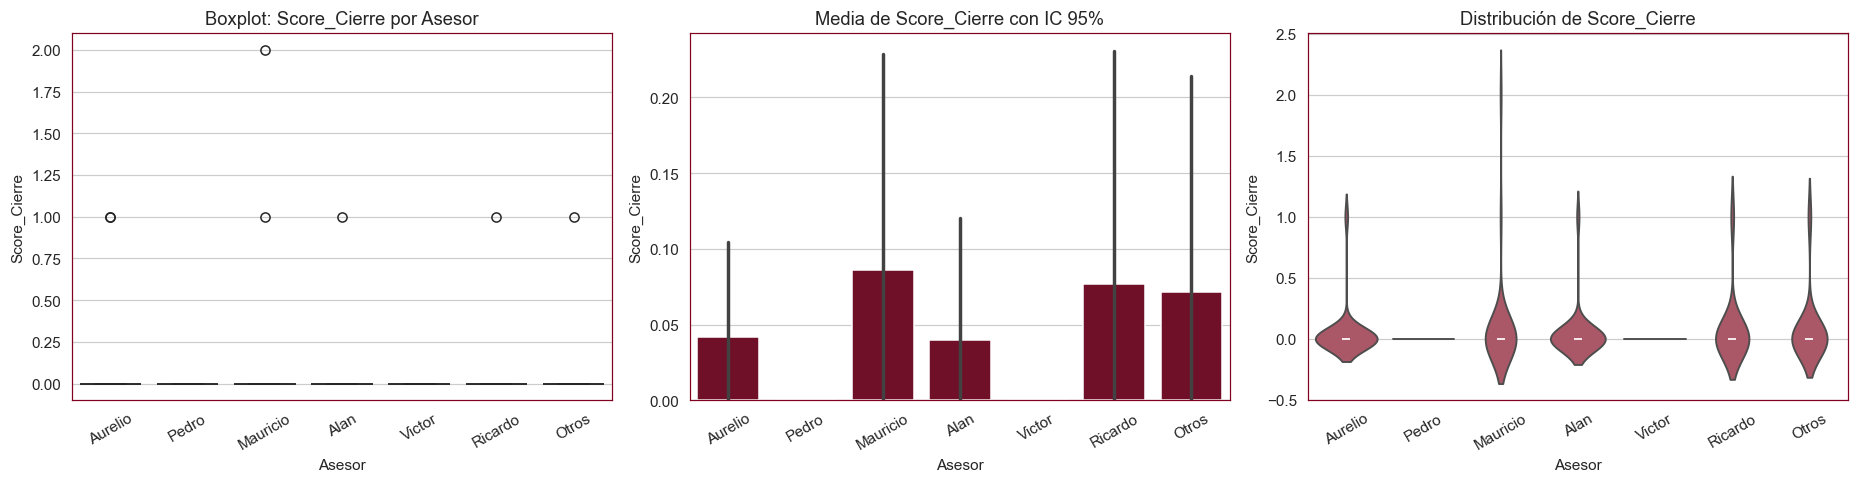

In [4]:
graficas_clasicas(b, "Score_Cierre", "Asesor")

### ANOVA de una vía — `Score_Cierre ~ Asesor`

In [5]:
m1 = anova_oneway(b, "Score_Cierre", "Asesor")

scipy.stats.f_oneway  →  F = 0.6819   p-value = 0.664435
Decisión: p ≥ 0.05 → NO hay evidencia de que el factor influya en la media


,df,sum_sq,mean_sq,F,PR(>F)
Asesor,6.0,0.2040,0.0340,0.6819,0.6644
Residual,190.0,9.4712,0.0498,NaN,NaN


### ANOVA multifactorial — `Score_Cierre ~ Asesor + Prueba_Manejo + Asesor:Prueba_Manejo`

,df,sum_sq,mean_sq,F,PR(>F)
Asesor,6.0,0.2040,0.0340,0.7050,0.6459
Prueba_Manejo,1.0,0.2085,0.2085,4.3253,0.0389
Asesor:Prueba_Manejo,6.0,0.4393,0.0732,1.5184,0.1743
Residual,183.0,8.8234,0.0482,NaN,NaN


R² del modelo factorial = 0.0880


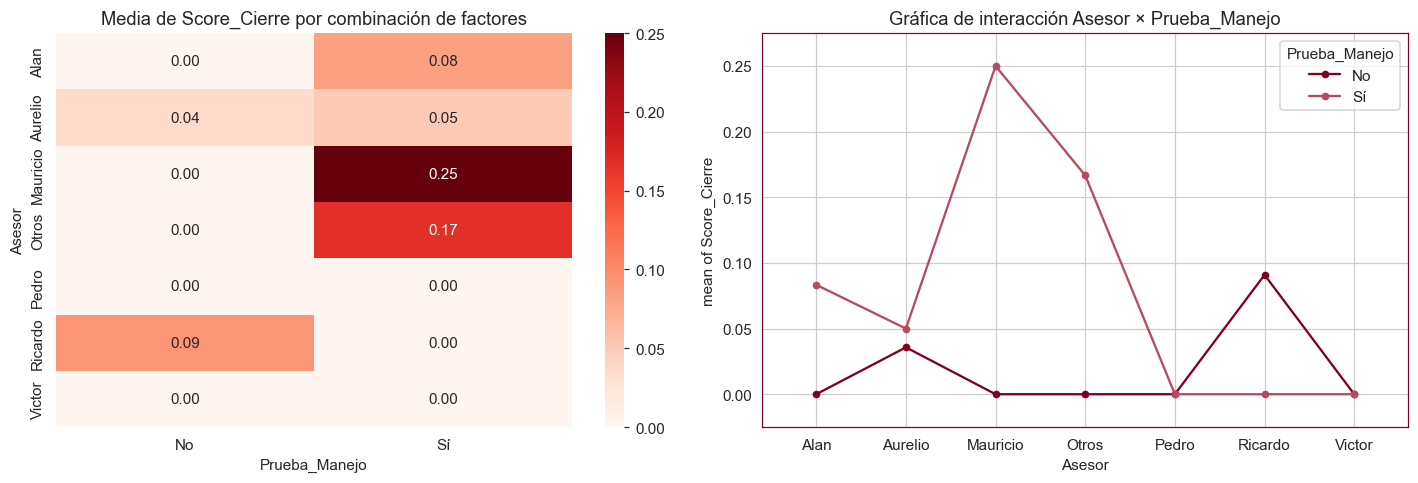

In [6]:
m1f = anova_factorial(b, "Score_Cierre ~ Asesor + Prueba_Manejo + Asesor:Prueba_Manejo",
                      "Score_Cierre", "Asesor", "Prueba_Manejo")

**Conclusiones Base 1.** El asesor por sí solo **no** explica diferencias en el cierre (one-way p = 0.664): el piso es homogéneo entre asesores. En el modelo factorial, la **prueba de manejo sí es significativa (p = 0.039)**: las visitas con prueba de manejo muestran mayor avance a crédito/venta. La interacción asesor × prueba **no** es significativa (p = 0.174) → el efecto de la prueba de manejo es consistente sin importar quién atiende. Implicación para GAC: el driver es *llevar al cliente a la prueba*, no reasignar carteras entre asesores.

---
# Base 2 · Leads Reales (28 cortes mensuales de efectividad)
**Pregunta de negocio:** ¿la **conversión** (ventas / leads efectivos) cambia según el **nivel de efectividad** del mes y el **periodo** (2024 vs 2025-2026)?

**Preprocesamiento:** nulos imputados en la actividad previa (verificado: 0); outliers IQR sobre `Conversion` (0 detectados); **transformación:** `Periodo_Analisis` consolida 2025 y 2026 (2026 solo tiene 5 cortes) para que todas las celdas del factorial tengan réplicas. Se usa `Conversion` como objetivo (no `Efectividad_Leads`, porque el factor `Nivel_Efectividad` se derivó de esa misma columna y el análisis sería circular).

In [7]:
l = pd.read_csv("Leads Reales.csv")
print("Registros:", len(l), "| Nulos totales:", int(l.isnull().sum().sum()))

# Transformación: periodo anual consolidado
l["Periodo_Analisis"] = np.where(l["Año"] == 2024, "2024", "2025-2026")

q1, q3 = l["Conversion"].quantile([0.25, 0.75])
iqr = q3 - q1
out = l[(l["Conversion"] < q1 - 1.5 * iqr) | (l["Conversion"] > q3 + 1.5 * iqr)]
print(f"Outliers IQR sobre Conversion: {len(out)}")
l.groupby(["Nivel_Efectividad", "Periodo_Analisis"])["Conversion"].agg(["count", "mean"]).round(3)

Registros: 28 | Nulos totales: 0
Outliers IQR sobre Conversion: 0


count   mean
Nivel_Efectividad Periodo_Analisis              
Alta              2024                  3  3.967
                  2025-2026             3  3.933
Baja              2024                  3  3.033
                  2025-2026             5  4.720
Media             2024                  5  2.860
                  2025-2026             9  5.033

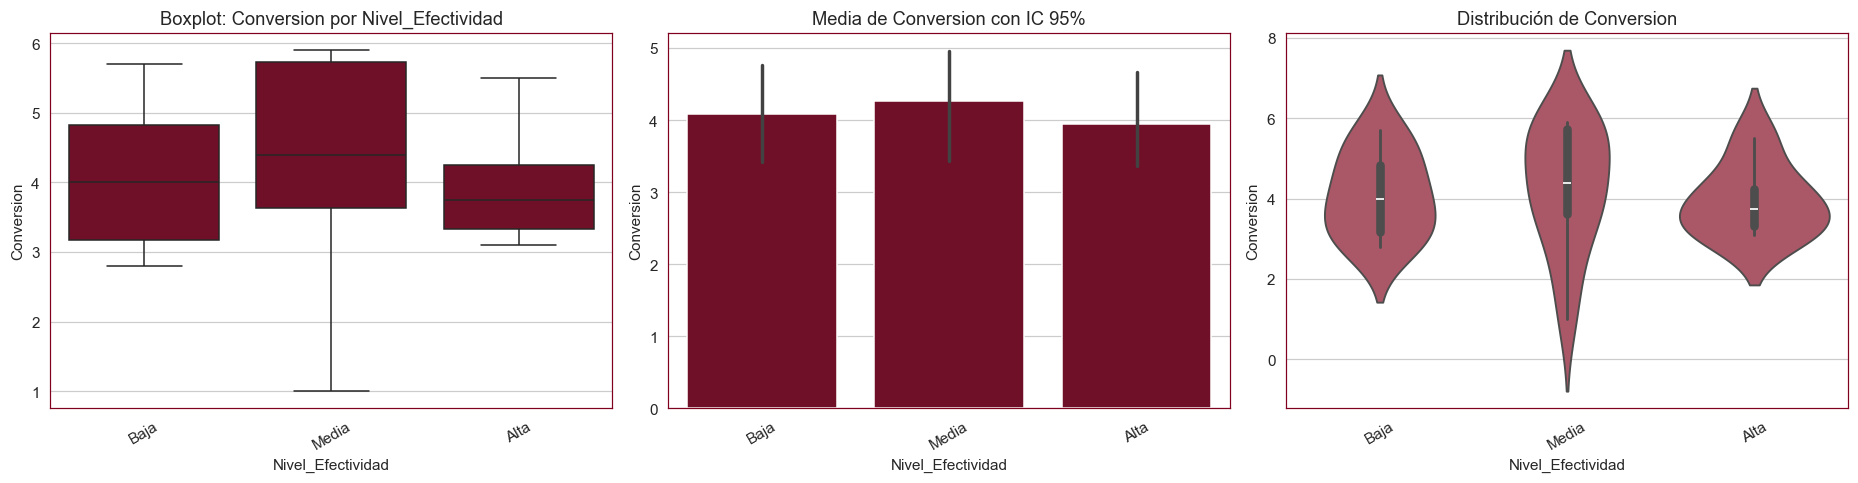

In [8]:
orden_nivel = ["Baja", "Media", "Alta"]
graficas_clasicas(l, "Conversion", "Nivel_Efectividad", orden=orden_nivel)

### ANOVA de una vía — `Conversion ~ Nivel_Efectividad`

In [9]:
m2 = anova_oneway(l, "Conversion", "Nivel_Efectividad")

scipy.stats.f_oneway  →  F = 0.1289   p-value = 0.879608
Decisión: p ≥ 0.05 → NO hay evidencia de que el factor influya en la media


,df,sum_sq,mean_sq,F,PR(>F)
Nivel_Efectividad,2.0,0.4305,0.2153,0.1289,0.8796
Residual,25.0,41.7380,1.6695,NaN,NaN


### ANOVA multifactorial — `Conversion ~ Nivel_Efectividad * Periodo_Analisis`

,df,sum_sq,mean_sq,F,PR(>F)
Nivel_Efectividad,2.0,0.4305,0.2153,0.2232,0.8018
Periodo_Analisis,1.0,15.4757,15.4757,16.0446,0.0006
Nivel_Efectividad:Periodo_Analisis,2.0,5.0423,2.5212,2.6138,0.0958
Residual,22.0,21.2200,0.9645,NaN,NaN


R² del modelo factorial = 0.4968


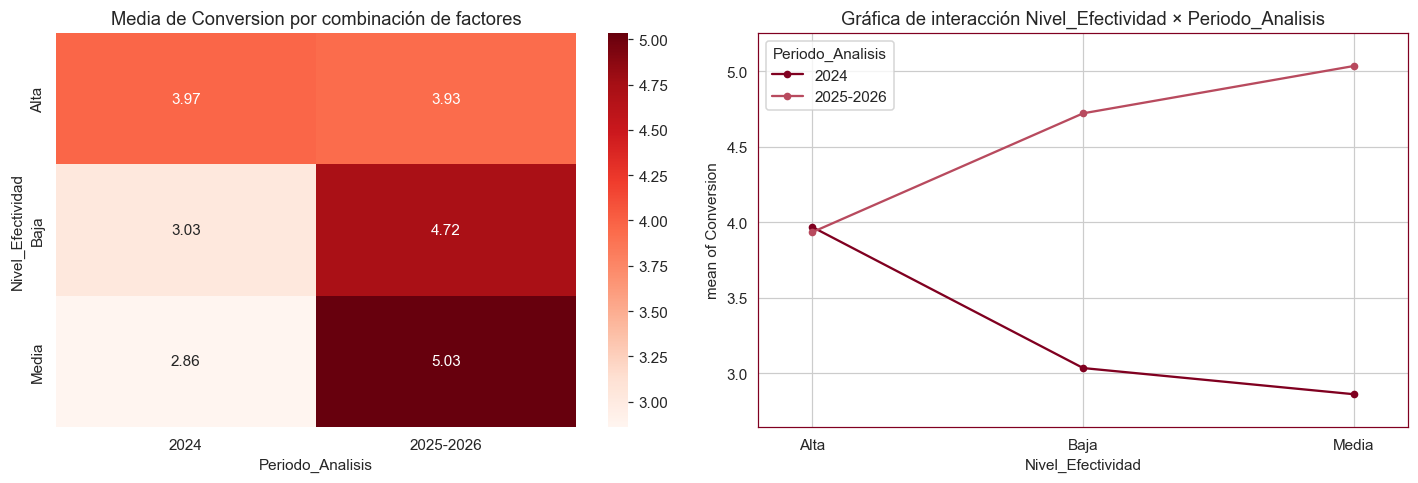

In [10]:
m2f = anova_factorial(l, "Conversion ~ Nivel_Efectividad + Periodo_Analisis + Nivel_Efectividad:Periodo_Analisis",
                      "Conversion", "Nivel_Efectividad", "Periodo_Analisis")

**Conclusiones Base 2.** El nivel de efectividad (Alta/Media/Baja, definido sobre volumen de leads efectivos) **no** se traduce en mejor conversión (one-way p = 0.880): filtrar más leads no garantiza cerrar más. El **periodo sí es significativo (p = 0.0006)**: la conversión cambió entre 2024 y 2025-2026. La interacción es marginal (p = 0.096): en 2025-2026 los meses de efectividad "Baja" convirtieron incluso mejor que los "Alta". Implicación: la eficiencia de cierre depende más del contexto del periodo que del volumen de leads efectivos.

---
# Base 3 · Base de Leads en Plaza Angelópolis (208 leads)
**Pregunta de negocio:** ¿la **temperatura del lead** (interés declarado) depende del **producto** y del **estado** final del lead?

**Preprocesamiento:** 0 nulos (verificado). **Transformaciones:** (1) `Temperatura` → `Score_Temperatura` ordinal (Bajo = 1, Interés Medio = 2, Muy Interesado = 3); (2) los productos con muy pocos registros (GS8: 7, GS4 MAX: 2, GN8: 1, AION: 1, "Sin especificar": 14) se excluyen del análisis para que el factorial sea de rango completo → quedan **EMZOOM (107) y EMKOO (76)**. La revisión IQR marca como "outliers" a los leads de temperatura Baja/Muy Interesada por ser categorías menos frecuentes; **se conservan** porque son categorías ordinales válidas, no errores.

In [11]:
bl = pd.read_csv("base_leads_limpia.csv")
print("Registros:", len(bl), "| Nulos totales:", int(bl.isnull().sum().sum()))

# Transformaciones
bl["Score_Temperatura"] = bl["Temperatura"].map(
    {"Lead Interes Bajo": 1, "Lead Interes Medio": 2, "Lead Muy Interesado": 3})
bl2 = bl[bl["Producto"].isin(["EMZOOM", "EMKOO"])].copy()
print("Registros en análisis (EMZOOM + EMKOO):", len(bl2))
print(pd.crosstab(bl2["Producto"], bl2["Estado"]))
bl2.groupby("Producto")["Score_Temperatura"].agg(["count", "mean", "std"]).round(3)

Registros: 208 | Nulos totales: 0
Registros en análisis (EMZOOM + EMKOO): 183
Estado    Contactado  Finalizado  Ventas
Producto                                
EMKOO             31          43       2
EMZOOM            35          66       6


,count,mean,std
Producto,,,
EMKOO,76,2.066,0.250
EMZOOM,107,2.093,0.377


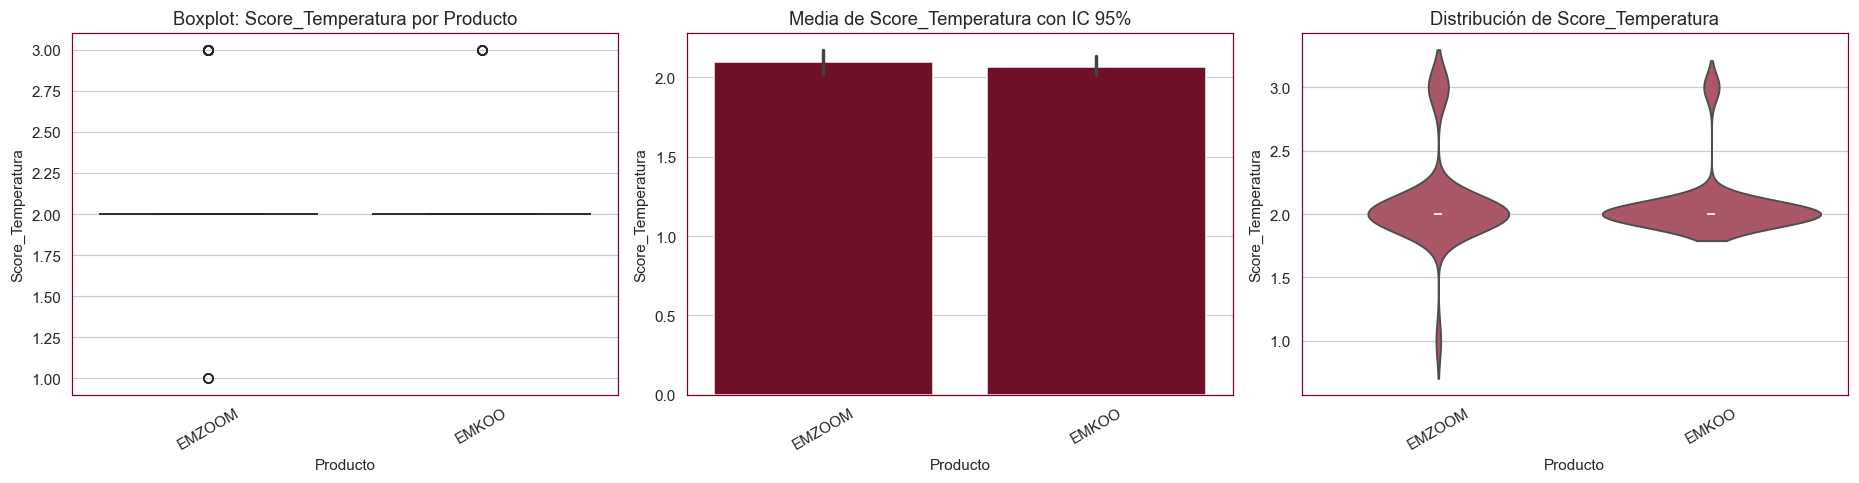

In [12]:
graficas_clasicas(bl2, "Score_Temperatura", "Producto")

### ANOVA de una vía — `Score_Temperatura ~ Producto`

In [13]:
m3 = anova_oneway(bl2, "Score_Temperatura", "Producto")

scipy.stats.f_oneway  →  F = 0.3120   p-value = 0.577159
Decisión: p ≥ 0.05 → NO hay evidencia de que el factor influya en la media


,df,sum_sq,mean_sq,F,PR(>F)
Producto,1.0,0.0340,0.034,0.312,0.5772
Residual,181.0,19.7365,0.109,NaN,NaN


### ANOVA multifactorial — `Score_Temperatura ~ Producto * Estado`

,df,sum_sq,mean_sq,F,PR(>F)
Producto,1.0,0.0340,0.0340,0.4940,0.4831
Estado,2.0,7.1873,3.5937,52.1889,0.0000
Producto:Estado,2.0,0.3612,0.1806,2.6227,0.0754
Residual,177.0,12.1880,0.0689,NaN,NaN


R² del modelo factorial = 0.3835


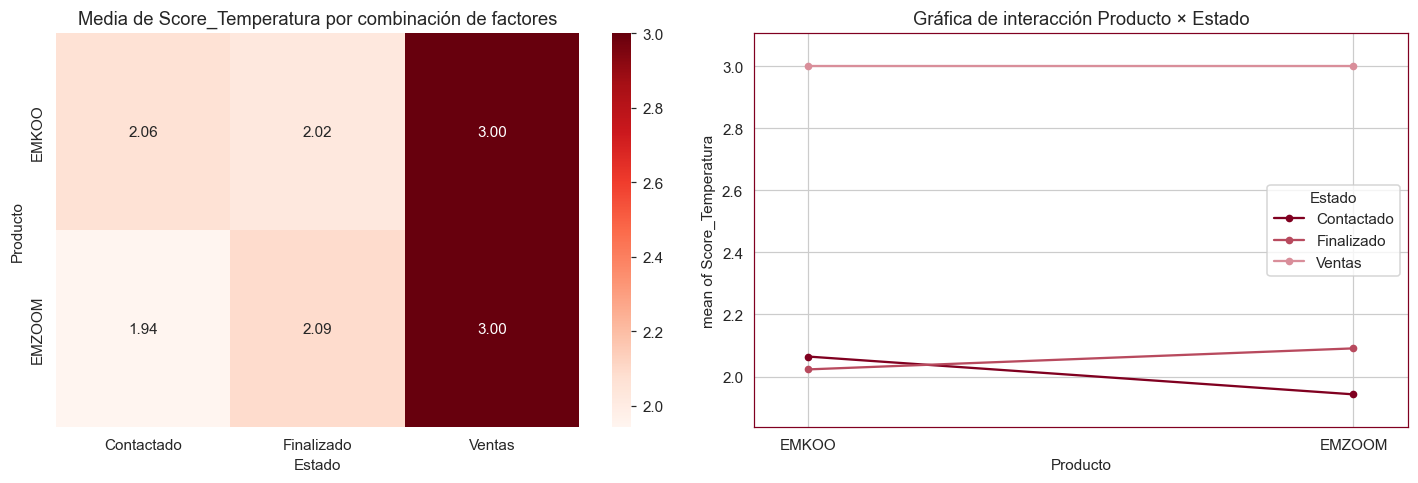

In [14]:
m3f = anova_factorial(bl2, "Score_Temperatura ~ Producto + Estado + Producto:Estado",
                      "Score_Temperatura", "Producto", "Estado")

**Conclusiones Base 3.** El producto **no** determina la temperatura del lead (one-way p = 0.577): EMZOOM y EMKOO atraen el mismo perfil de interés. El **estado del lead sí es altamente significativo (p < 0.0001)**: los leads que terminan en venta registran temperatura máxima (3.0) frente a ~2.0 de los que quedan contactados/finalizados — la temperatura capturada en plaza sí anticipa el cierre. La interacción producto × estado no es significativa (p = 0.075). Implicación: conviene registrar la temperatura con disciplina porque es un predictor útil de venta, igual para ambos productos.

---
# Base 4 · Resumen Mensual de resultados (30 meses)
**Pregunta de negocio:** ¿el **% de cumplimiento del objetivo de ventas** cambió entre periodos (2024 vs 2025-2026) y entre **semestres**?

**Preprocesamiento:** 0 nulos (verificado); IQR marca 3 meses extremos en `% CAL Ventas` que **se conservan** (son meses reales de muy alto/bajo cumplimiento, no errores). **Transformación:** `Semestre` (S1/S2) a partir del número de mes y `Periodo_Analisis` consolidado igual que en la Base 2.

In [15]:
r = pd.read_csv("base_resumen_limpio.csv")
print("Registros:", len(r), "| Nulos totales:", int(r.isnull().sum().sum()))

# Transformaciones
r["CAL_Ventas"] = r["% CAL Ventas"]
r["Semestre"] = np.where(r["Mes"] <= 6, "S1", "S2")
r["Periodo_Analisis"] = np.where(r["Año"] == 2024, "2024", "2025-2026")

q1, q3 = r["CAL_Ventas"].quantile([0.25, 0.75])
iqr = q3 - q1
out = r[(r["CAL_Ventas"] < q1 - 1.5 * iqr) | (r["CAL_Ventas"] > q3 + 1.5 * iqr)]
print(f"Outliers IQR sobre CAL_Ventas: {len(out)} (se conservan: meses reales)")
r.groupby(["Periodo_Analisis", "Semestre"])["CAL_Ventas"].agg(["count", "mean"]).round(3)

Registros: 30 | Nulos totales: 0
Outliers IQR sobre CAL_Ventas: 3 (se conservan: meses reales)


count   mean
Periodo_Analisis Semestre              
2024             S1            5  0.460
                 S2            6  0.975
2025-2026        S1           12  0.979
                 S2            7  0.949

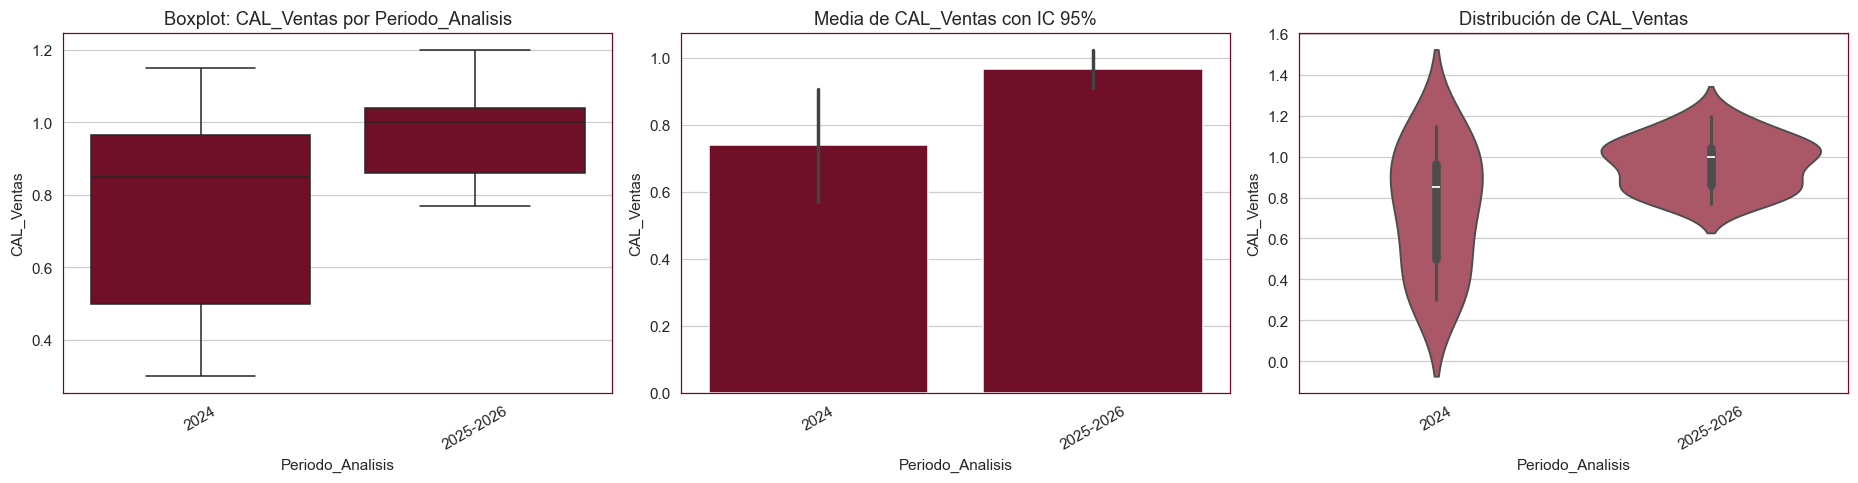

In [16]:
graficas_clasicas(r, "CAL_Ventas", "Periodo_Analisis")

### ANOVA de una vía — `CAL_Ventas ~ Periodo_Analisis`

In [17]:
m4 = anova_oneway(r, "CAL_Ventas", "Periodo_Analisis")

scipy.stats.f_oneway  →  F = 8.3585   p-value = 0.007341
Decisión: p < 0.05 → el factor SÍ influye en la media


,df,sum_sq,mean_sq,F,PR(>F)
Periodo_Analisis,1.0,0.3589,0.3589,8.3585,0.0073
Residual,28.0,1.2024,0.0429,NaN,NaN


### ANOVA multifactorial — `CAL_Ventas ~ Periodo_Analisis * Semestre`

,df,sum_sq,mean_sq,F,PR(>F)
Periodo_Analisis,1.0,0.3589,0.3589,19.6502,0.0002
Semestre,1.0,0.2254,0.2254,12.3384,0.0016
Periodo_Analisis:Semestre,1.0,0.5021,0.5021,27.4876,0.0000
Residual,26.0,0.4749,0.0183,NaN,NaN


R² del modelo factorial = 0.6958


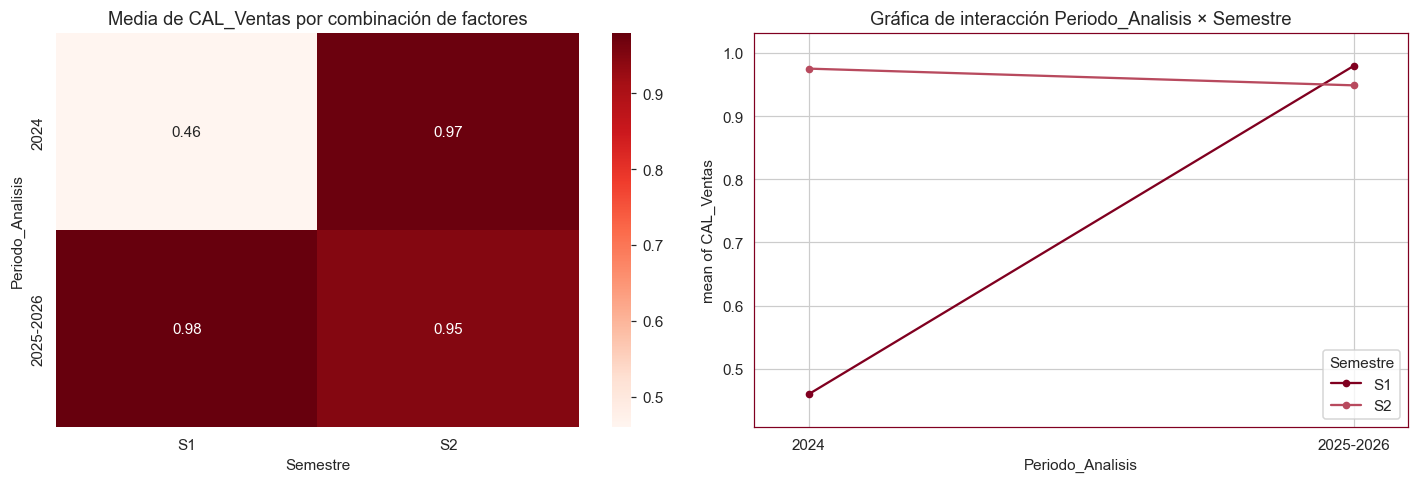

In [18]:
m4f = anova_factorial(r, "CAL_Ventas ~ Periodo_Analisis + Semestre + Periodo_Analisis:Semestre",
                      "CAL_Ventas", "Periodo_Analisis", "Semestre")

**Conclusiones Base 4.** Resultado más contundente del estudio: el **periodo (p = 0.0073 en one-way; p = 0.0002 en el factorial)**, el **semestre (p = 0.0016)** y su **interacción (p < 0.0001)** son todos significativos, con R² = 0.70. El cumplimiento del objetivo de ventas mejoró fuertemente en 2025-2026, pero el patrón se invierte por semestre (la gráfica de interacción muestra el cruce): en 2024 el segundo semestre era el flojo; en 2025-2026 el primer semestre es el más bajo. Implicación: la planeación de objetivos debe revisarse por semestre, no solo anual.

---
# Base 5 · Funnel Mensual (18 meses × 8 etapas = 144 observaciones)
**Pregunta de negocio:** ¿el **volumen de registros** difiere entre las **etapas del embudo** y entre **años**?

**Preprocesamiento:** 0 nulos (verificado). **Transformaciones:** (1) formato ancho → largo con `melt` (cada renglón = mes × etapa), (2) extracción del `Año` desde la etiqueta de mes. Los 19 "outliers" IQR corresponden a los meses pico en las etapas superiores del embudo (Leads Generados); se conservan porque reflejan campañas reales de captación.

In [19]:
f = pd.read_csv("funnel_mensual.csv")
print("Registros:", len(f), "| Nulos totales:", int(f.isnull().sum().sum()))

etapas = ["Leads_Generados", "Leads_Efectivos", "Cita_Programada", "Cita_Efectiva",
          "Prueba_Manejo", "SDC_Generada", "SDC_Aprobada", "Formalizado"]
f["Año"] = f["Mes"].str.extract(r"(\d{4})").astype(int)

# Transformación: formato largo
long = f.melt(id_vars=["Mes", "Año"], value_vars=etapas,
              var_name="Etapa", value_name="Registros")
long["Ano"] = long["Año"].astype(str)
print("Formato largo:", long.shape)

q1, q3 = long["Registros"].quantile([0.25, 0.75])
iqr = q3 - q1
out = long[(long["Registros"] < q1 - 1.5 * iqr) | (long["Registros"] > q3 + 1.5 * iqr)]
print(f"Outliers IQR sobre Registros: {len(out)} (meses pico de captación, se conservan)")
long.groupby("Etapa")["Registros"].agg(["count", "mean"]).round(1).reindex(etapas)

Registros: 18 | Nulos totales: 0
Formato largo: (144, 5)
Outliers IQR sobre Registros: 19 (meses pico de captación, se conservan)


,count,mean
Etapa,,
Leads_Generados,18,1206.9
Leads_Efectivos,18,809.5
Cita_Programada,18,253.9
Cita_Efectiva,18,188.4
Prueba_Manejo,18,116.8
SDC_Generada,18,94.9
SDC_Aprobada,18,37.9
Formalizado,18,18.5


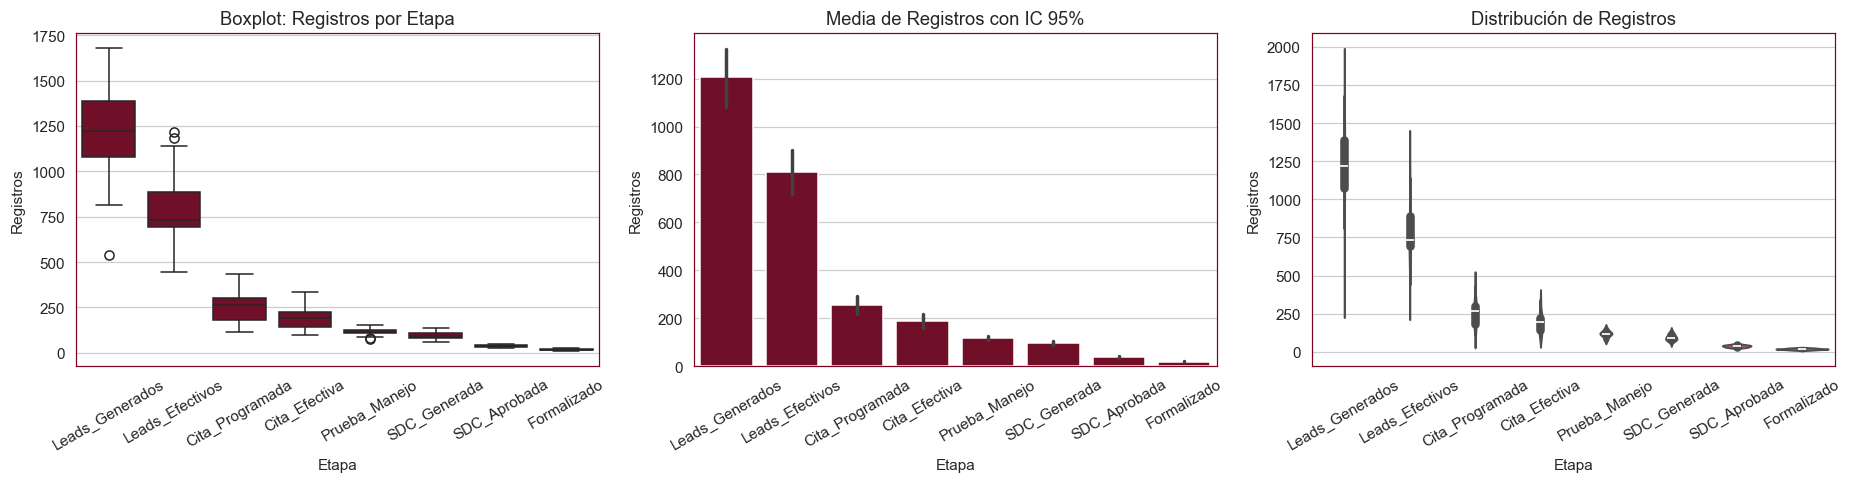

In [20]:
graficas_clasicas(long, "Registros", "Etapa", orden=etapas)

### ANOVA de una vía — `Registros ~ Etapa`

In [21]:
m5 = anova_oneway(long, "Registros", "Etapa")

scipy.stats.f_oneway  →  F = 202.1240   p-value = 0.000000
Decisión: p < 0.05 → el factor SÍ influye en la media


,df,sum_sq,mean_sq,F,PR(>F)
Etapa,7.0,2.352496e+07,3.360709e+06,202.124,0.0
Residual,136.0,2.261267e+06,1.662696e+04,NaN,NaN


### ANOVA multifactorial — `Registros ~ Etapa * Año`

,df,sum_sq,mean_sq,F,PR(>F)
Etapa,7.0,2.352496e+07,3.360709e+06,257.0229,0.0000
Ano,1.0,1.981351e+05,1.981351e+05,15.1531,0.0002
Etapa:Ano,7.0,3.894647e+05,5.563782e+04,4.2551,0.0003
Residual,128.0,1.673667e+06,1.307552e+04,NaN,NaN


R² del modelo factorial = 0.9351


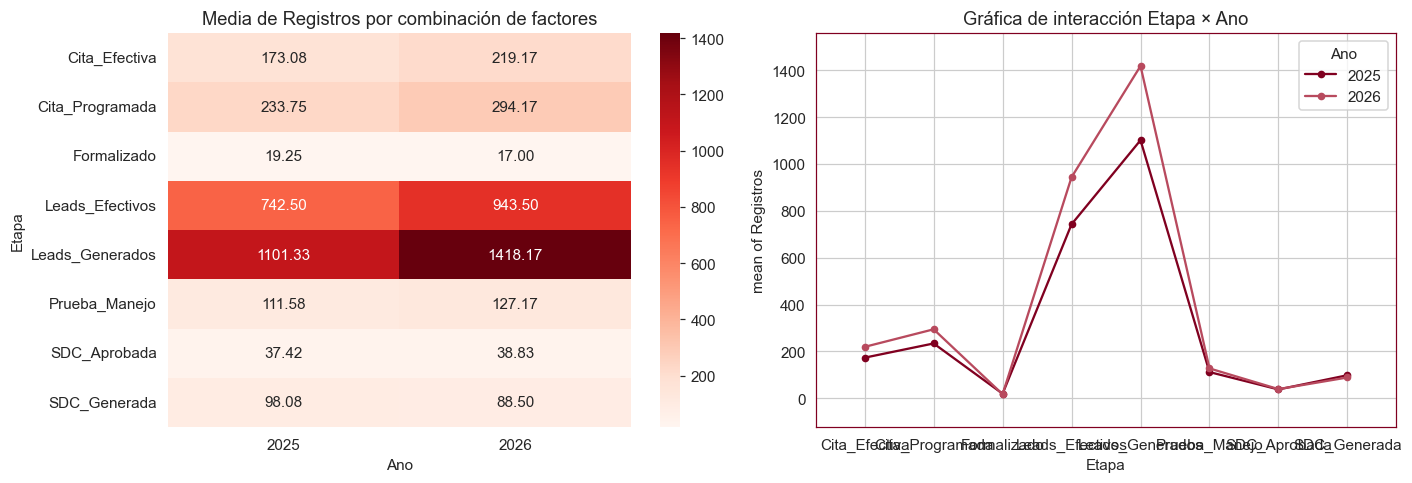

In [22]:
m5f = anova_factorial(long, "Registros ~ Etapa + Ano + Etapa:Ano",
                      "Registros", "Etapa", "Ano")

**Conclusiones Base 5.** La etapa del embudo explica el 91% de la varianza (F = 202.1, p < 10⁻⁶⁷): la estructura de embudo —muchos leads arriba, pocos formalizados abajo— es masiva y consistente. El **año también es significativo (p = 0.0002)** y la **interacción etapa × año (p = 0.0003)** muestra que el embudo de 2026 trae más volumen arriba pero mantiene la misma tasa de estrangulamiento en Cita→Prueba→SDC. Implicación: el cuello de botella no desapareció con más captación; el esfuerzo debe ponerse en las etapas medias (citas y pruebas de manejo), exactamente lo que la Base 1 señala como driver del cierre.

---
# Conclusiones generales

| Base | ANOVA una vía | ANOVA multifactorial | Hallazgo clave |
|------|---------------|----------------------|----------------|
| Bitácora de Piso | Asesor: p = 0.664 (n.s.) | Prueba de manejo: **p = 0.039** ✔ · interacción n.s. | La prueba de manejo mueve el cierre; el asesor no |
| Leads Reales | Nivel de efectividad: p = 0.880 (n.s.) | Periodo: **p = 0.0006** ✔ · interacción p = 0.096 | Convertir no depende del volumen efectivo, sí del periodo |
| Base de Leads | Producto: p = 0.577 (n.s.) | Estado: **p < 0.0001** ✔ · interacción p = 0.075 | La temperatura del lead anticipa la venta, igual en ambos productos |
| Resumen Mensual | Periodo: **p = 0.0073** ✔ | Periodo **p = 0.0002**, Semestre **p = 0.0016**, **interacción p < 0.0001** (R² = 0.70) | El cumplimiento de objetivo cambió de régimen entre 2024 y 2025-2026 |
| Funnel Mensual | Etapa: **p < 10⁻⁶⁷** ✔ (R² = 0.91) | Etapa, Año e **interacción p = 0.0003** ✔ | El cuello de botella Cita→Prueba→SDC persiste pese a mayor captación |

**Insight transversal:** las tres bases que tocan el proceso comercial (Bitácora, Funnel y Leads de plaza) apuntan al mismo punto — *la prueba de manejo y la gestión de citas son la palanca del cierre*; mientras que las bases de resultados (Leads Reales, Resumen) muestran que el cambio vino del **periodo/régimen**, no de la mezcla de productos ni del volumen de leads.

**Nota metodológica:** se reportan resultados significativos y no significativos por igual. Donde un factor no resultó significativo (asesor, producto, nivel de efectividad) la conclusión de negocio es igual de accionable: no hay evidencia de que mover ese factor cambie la media.